# 05 — Full run over the whole lightcone

This notebook processes all 67 slices (324 M galaxies, z = 0–4) and then looks at the complete
Roman-like parent catalog. It is meant for an exclusive CPU node (Perlmutter: 128 physical
cores, 512 GB): slices are processed in parallel, one per worker process, with a peak of a few GB
per worker. Wall time is dominated by reading the 340 GB of input from CFS.

The same run from the command line is
`romanmock run <config.yaml> --workers 32` (the notebook writes that config file).

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # diffsky imports JAX; avoid CUDA probing on login nodes
import warnings
warnings.filterwarnings("ignore", message="Version checking")

import numpy as np
import matplotlib.pyplot as plt
import opencosmo as oc

from romanmock import plotting
plotting.use_style()

CATALOG = "/global/cfs/cdirs/m4943/Simulations/sdss_feniks_hizels_260710_09_07_2026"
WORK = os.path.join(os.environ.get("PSCRATCH", "/tmp"), "romanmock_demo")   # outputs of the tutorials
os.makedirs(WORK, exist_ok=True)

In [2]:
import time
from romanmock import RomanMockConfig, RomanMockPipeline

from romanmock.io import memory_budget_gb, suggest_n_workers

# one slice per process, ~4.5 GB peak each: size the pool by the memory this session may use
# (node memory, or the per-user cgroup cap on a NERSC login node)
N_WORKERS = suggest_n_workers(max_workers=32)
print(f"memory budget {memory_budget_gb():.0f} GB -> {N_WORKERS} worker(s)")
OUT_DIR = os.path.join(WORK, "full")

cfg = RomanMockConfig.from_dict({
    "catalog": {"path": CATALOG},                        # every slice, z = 0-4
    "output": {"dir": OUT_DIR, "overwrite": False,
               "passthrough_columns": ["ra", "dec", "redshift_true"]},          # plus redshift_rsd, redshift_assigned, id_outcome, identification columns
    "line_set": "roman_transitions",
    "sensitivity": {"type": "constant", "flux_limit": 1e-16, "wave_range": [10000.0, 19300.0]},
    "detection": {"type": "threshold"},
    "confusion": {"type": "matrix", "default_p_fail": 0.02, "rows": {      # assumed scenario, not a calibration
        "Ha":        {"OIII_5007": 0.05, "OII_3727": 0.03, "fail": 0.05},
        "OIII_5007": {"Ha": 0.15, "OII_3727": 0.05, "fail": 0.05},
        "OII_3727":  {"Ha": 0.15, "OIII_5007": 0.10, "fail": 0.10},
        "Hb":        {"Ha": 0.30, "OIII_5007": 0.30, "fail": 0.20}}},
    "seed": 2026,
})
os.makedirs(OUT_DIR, exist_ok=True)
cfg.to_yaml(os.path.join(OUT_DIR, "config.yaml"))     # reusable with: romanmock run .../config.yaml --workers 32
pipe = RomanMockPipeline(cfg)
print(pipe.line_set.describe())

memory budget 505 GB -> 32 worker(s)


LineSet 'roman_transitions': bit -> feature (rest wavelength [A]; components)
  bit  0 (value          1): Ha          6564.723  Ba_alpha_6563  H-alpha 6563
  bit  1 (value          2): Hb          4862.763  Ba_beta_4861  H-beta 4861
  bit  2 (value          4): OIII_5007   5008.314  O_III_5007  [O III] 5007
  bit  3 (value          8): OIII_4959   4960.370  O_III_4959  [O III] 4959
  bit  4 (value         16): OII_3727    3728.619  O_II_3726+O_II_3729  [O II] 3726+3729 blend
  bit  5 (value         32): SIII_9532   9533.378  S_III_9532  [S III] 9532
  bit  6 (value         64): SIII_9069   9071.246  S_III_9069  [S III] 9069
  bit  7 (value        128): OIII_4363   4364.294  O_III_4363  [O III] 4363 (auroral)
  bit  8 (value        256): SIII_6312   6313.902  S_III_6312  [S III] 6312 (auroral)


In [3]:
t0 = time.time()
outputs = pipe.run(n_workers=N_WORKERS)               # existing outputs are skipped (output.overwrite = False)
print(f"{len(outputs)} slices, {(time.time() - t0) / 60:.1f} min")

[romanmock] step  105  z=[3.548,3.631]  n=2,402,205 -> lc_cores-105.romanmock.hdf5: 2,898 galaxies (0.12%)


[romanmock] step  100  z=[3.763,3.855]  n=2,427,416 -> lc_cores-100.romanmock.hdf5: 2,707 galaxies (0.11%)


[romanmock] step  102  z=[3.631,3.763]  n=3,763,996 -> lc_cores-102.romanmock.hdf5: 4,085 galaxies (0.11%)


[romanmock] step  107  z=[3.427,3.548]  n=4,035,691 -> lc_cores-107.romanmock.hdf5: 5,434 galaxies (0.13%)


[romanmock] step  110  z=[3.313,3.427]  n=4,136,923 -> lc_cores-110.romanmock.hdf5: 5,562 galaxies (0.13%)


[romanmock] step   97  z=[3.855,4.000]  n=3,453,453 -> lc_cores-97.romanmock.hdf5: 2,901 galaxies (0.08%)


... (58 outputs left out)

[romanmock] step  230  z=[1.107,1.152]  n=6,306,879 -> lc_cores-230.romanmock.hdf5: 2,013,382 galaxies (31.92%)


[romanmock] step  194  z=[1.494,1.544]  n=6,050,518 -> lc_cores-194.romanmock.hdf5: 1,867,342 galaxies (30.86%)


[romanmock] step  198  z=[1.433,1.494]  n=7,925,280 -> lc_cores-198.romanmock.hdf5: 2,482,197 galaxies (31.32%)


66 slices, 0.9 min


## The parent catalog

All slices re-open as one `opencosmo.Lightcone`. Only the columns needed below are read.

In [4]:
from romanmock.diagnostics import outcome_summary
from romanmock.selection import sky_area_deg2

parent = pipe.open_parent()
area = sky_area_deg2(parent, nside=256)
print(f"{len(parent):,} galaxies with at least one detected line, z_range {parent.z_range}, area {area:.0f} deg²")
cols = ["redshift_assigned", "redshift_rsd", "id_outcome", "n_det", "line_true", "line_assigned"]
t0 = time.time()
pdata = parent.select(*cols).get_data("numpy", wrap_single=True)
print(f"read {len(cols)} columns in {time.time() - t0:.0f} s")
summary = outcome_summary(pdata)
for k, v in summary.items():
    print(f"  {k:<15s} {v:>12,}  ({100 * v / len(parent):5.2f}%)")

64,556,046 galaxies with at least one detected line, z_range (0.024464831804281495, 4.0), area 2116 deg²


read 6 columns in 1 s
  NOT_DETECTED               0  ( 0.00%)
  MULTI_LINE        30,804,054  (47.72%)
  SINGLE_CORRECT    29,246,016  (45.30%)
  SINGLE_MISID       2,881,250  ( 4.46%)
  SINGLE_FAILED      1,624,726  ( 2.52%)


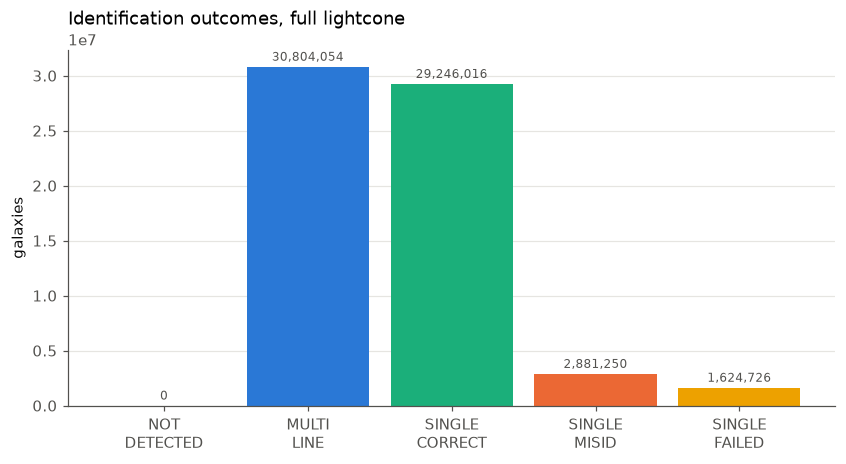

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.2))
plotting.bar(ax, [k.replace("_", "\n") for k in summary], list(summary.values()), colors=[plotting.OUTCOME_COLORS[k] for k in summary])
ax.set_ylabel("galaxies"); ax.set_title("Identification outcomes, full lightcone"); plt.show()

## Redshift distributions per assigned line

`dN/dz` per deg² of assigned redshift of the galaxies *assigned* each identity (what an observer would call the
Hα sample, the [O III] sample, ...). Multi-line galaxies are counted under their brightest line.

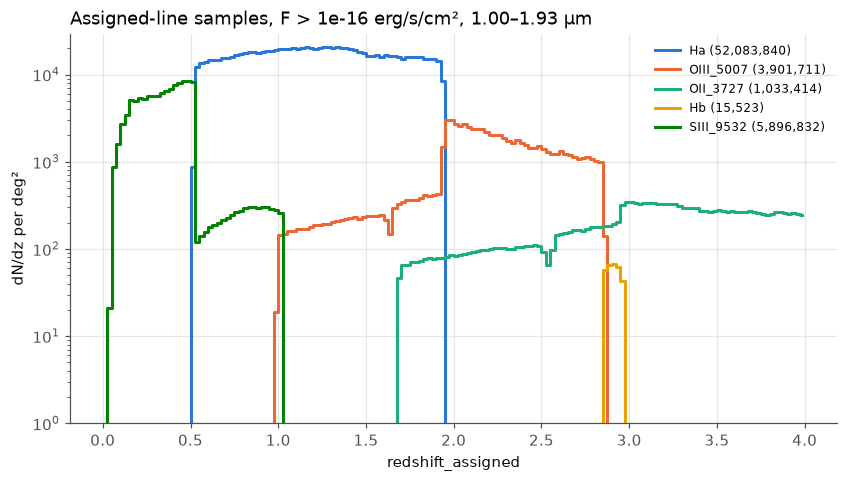

In [6]:
from romanmock.diagnostics import dndz

z_edges = np.linspace(0.0, 4.0, 161)
zc = 0.5 * (z_edges[1:] + z_edges[:-1])
has_z = np.isfinite(pdata["redshift_assigned"])
fig, ax = plt.subplots(figsize=(9, 4.6))
for name in ["Ha", "OIII_5007", "OII_3727", "Hb", "OIII_4959", "SIII_9532"]:
    sel = has_z & (pdata["line_assigned"] == pipe.line_set.bit(name))
    if sel.sum() == 0:
        continue
    y = dndz(pdata["redshift_assigned"][sel], z_edges, area)
    ax.step(zc, y, where="mid", color=plotting.feature_color(name), label=f"{name} ({sel.sum():,})")
ax.set_yscale("log"); ax.set_ylim(1, None)
ax.set_xlabel("redshift_assigned"); ax.set_ylabel("dN/dz per deg²"); ax.set_title("Assigned-line samples, F > 1e-16 erg/s/cm², 1.00–1.93 μm")
ax.legend(fontsize=8); plt.show()

## True versus assigned redshift

The density of galaxies in the (redshift_rsd, redshift_assigned) plane. Correct identifications lie on the
diagonal; each interloper track is the line ``(1+z_assigned) = (1+z_rsd) λ_i/λ_j``.

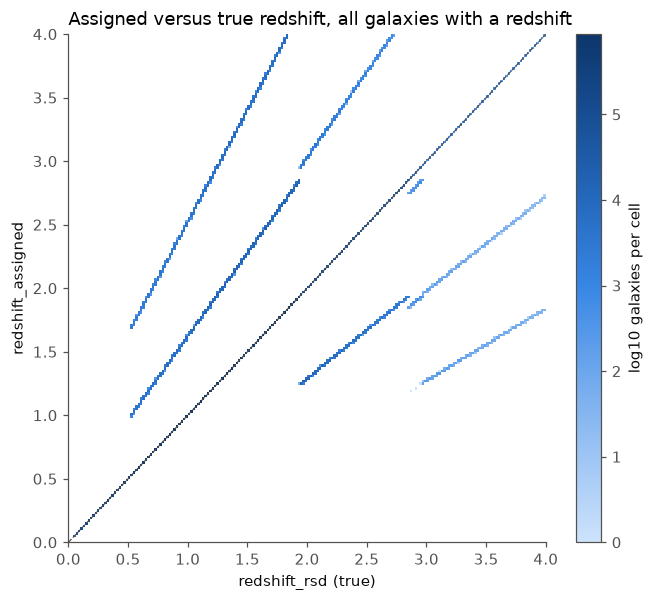

In [7]:
sel = has_z
H, xe, ye = np.histogram2d(pdata["redshift_rsd"][sel], pdata["redshift_assigned"][sel], bins=[np.linspace(0, 4, 201), np.linspace(0, 4, 201)])
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.pcolormesh(xe, ye, np.log10(np.where(H > 0, H, np.nan)).T, cmap=plotting.sequential_cmap())
plt.colorbar(im, ax=ax, label="log10 galaxies per cell")
ax.plot([0, 4], [0, 4], color=plotting.TEXT_SECONDARY, lw=0.8, ls="--")
ax.set_xlabel("redshift_rsd (true)"); ax.set_ylabel("redshift_assigned"); ax.set_title("Assigned versus true redshift, all galaxies with a redshift")
ax.grid(False); plt.show()

## Contamination of the Hα and [O III] samples

`f_{i→j}(B)`: the fraction of the assigned-*j* sample in a bin of assigned redshift whose true line is *i*
(plan comment 4). It depends on the confusion matrix *and* on the relative abundances of the
populations along the line of sight, so it is not constant even though the matrix is.

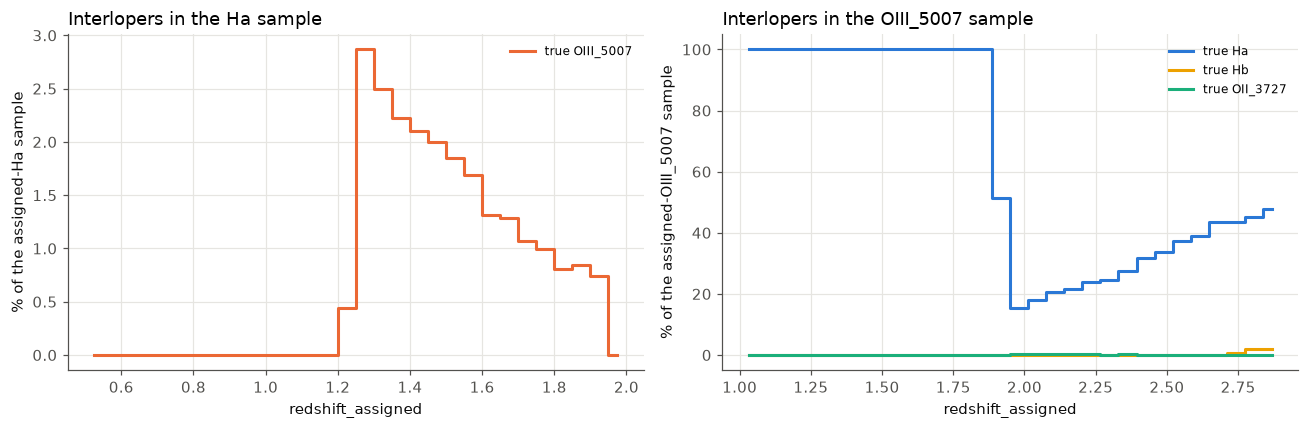

In [8]:
from romanmock.diagnostics import contamination_fraction

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (assigned, zr) in zip(axes, [("Ha", (0.5, 2.0)), ("OIII_5007", (1.0, 2.9))]):
    edges = np.linspace(*zr, 31)
    c = contamination_fraction(pdata, pipe.line_set, edges, assigned_line=assigned)
    zc = 0.5 * (edges[1:] + edges[:-1])
    for name in pipe.line_set.names:
        i = pipe.line_set.bit(name)
        if name == assigned or c["fraction"][i].max() < 0.002:
            continue
        ax.step(zc, 100 * c["fraction"][i], where="mid", color=plotting.feature_color(name), label=f"true {name}")
    ax.set_xlabel("redshift_assigned"); ax.set_ylabel(f"% of the assigned-{assigned} sample"); ax.set_title(f"Interlopers in the {assigned} sample")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Two features of these curves are properties of the mock rather than of the confusion matrix.
Below assigned redshift 1.9 the assigned-[O III] sample is *entirely* Hα interlopers: any galaxy whose
[O III] 5007 is detected there also has Hα (always brighter in diffsky) inside the bandpass, so it
is a multi-line detection and is counted under Hα; the only single-line "[O III]" objects are
misidentified Hα emitters. Likewise the [O III] → Hα contamination of the Hα sample switches on
at assigned redshift 1.2, where true [O III] emitters at z ≈ 1.9 (Hα just redshifted out of the grism)
start to be single-line detections.

## Completeness and the empirical confusion matrix

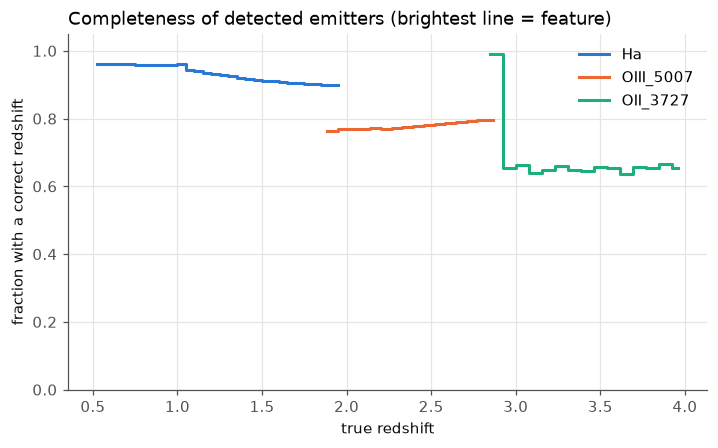

empirical confusion among single-line galaxies (rows true, columns assigned):
                   Ha        Hb OIII_5007 OIII_4959  OII_3727 SIII_9532 SIII_9069 OIII_4363 SIII_6312      fail
  Ha           0.8700    0.0000    0.0500    0.0000    0.0300    0.0000    0.0000    0.0000    0.0000    0.0500
  Hb           0.2998    0.2041    0.2952    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000    0.2008
  OIII_5007    0.1502    0.0000    0.7500    0.0000    0.0498    0.0000    0.0000    0.0000    0.0000    0.0500
  OIII_4959    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000
  OII_3727     0.1468    0.0000    0.1003    0.0000    0.6519    0.0000    0.0000    0.0000    0.0000    0.1010
  SIII_9532    0.0000    0.0000    0.0000    0.0000    0.0000    0.9800    0.0000    0.0000    0.0000    0.0200
  SIII_9069    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000
  OIII_4363    0.0000    0

In [9]:
from romanmock.diagnostics import completeness, empirical_confusion

fig, ax = plt.subplots()
for name, zr in [("Ha", (0.5, 2.0)), ("OIII_5007", (1.0, 2.9)), ("OII_3727", (1.7, 4.0))]:
    edges = np.linspace(*zr, 31)
    comp = completeness(pdata, pipe.line_set, edges, line=name)
    ax.step(0.5 * (edges[1:] + edges[:-1]), comp["completeness"], where="mid", color=plotting.feature_color(name), label=name)
ax.set_ylim(0, 1.05); ax.set_xlabel("true redshift"); ax.set_ylabel("fraction with a correct redshift")
ax.set_title("Completeness of detected emitters (brightest line = feature)"); ax.legend(); plt.show()

emp = empirical_confusion(pdata, pipe.line_set)
names = pipe.line_set.names + ["fail"]
print("empirical confusion among single-line galaxies (rows true, columns assigned):")
print("            " + " ".join(f"{n[:9]:>9s}" for n in names))
for i, n in enumerate(pipe.line_set.names):
    print(f"  {n[:9]:<9s} " + " ".join(f"{x:9.4f}" for x in emp[i]))

## Matching the emitter populations to the HLSS forecast

Wang et al. (2022, arXiv:2110.01829) tabulate the expected dN/dz per deg² of Hα and [O III]
emitters above a given line-flux limit (Tables 1–2, Galacticus on the UNIT lightcone). Those
numbers describe *true emitters before observational efficiency*, so the right quantity to match
is the mock's detected-line population in bins of true redshift, before any redshift assignment
or sample selection. `romanmock.reference_dndz` carries the tables; the comparison below uses the
run's flux limit (1e-16) and the A_V = 1.65 dust model.

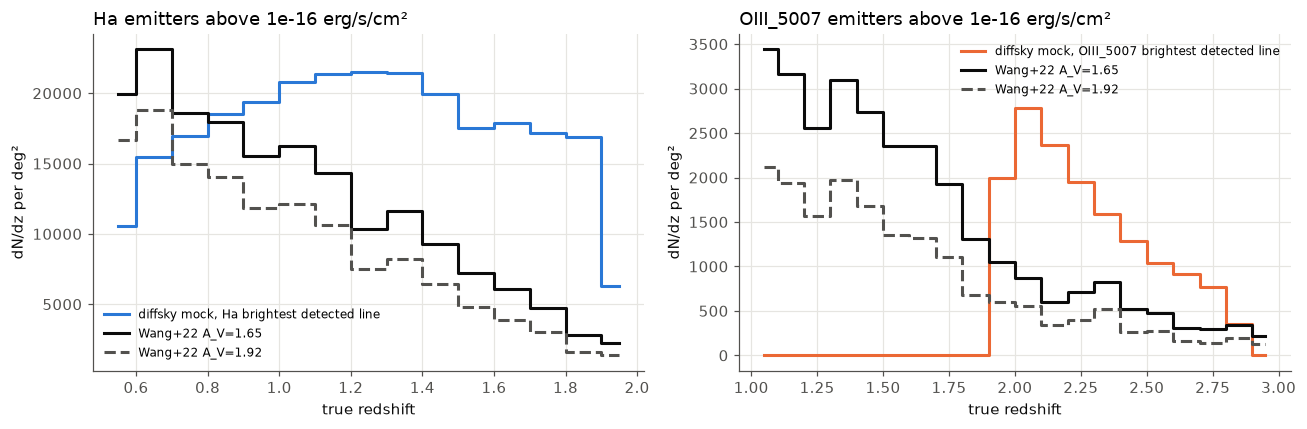

In [10]:
from romanmock.reference_dndz import wang2022_bins

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, ["Ha", "OIII_5007"]):
    edges, ref = wang2022_bins(name, 1e-16, 1.65)
    _, ref192 = wang2022_bins(name, 1e-16, 1.92)
    sel = pdata["line_true"] == pipe.line_set.bit(name)
    zc = 0.5 * (edges[1:] + edges[:-1])
    ax.step(zc, dndz(pdata["redshift_rsd"][sel], edges, area), where="mid", color=plotting.feature_color(name), label=f"diffsky mock, {name} brightest detected line")
    ax.step(zc, ref, where="mid", color=plotting.TEXT_PRIMARY, label="Wang+22 A_V=1.65")
    ax.step(zc, ref192, where="mid", color=plotting.TEXT_SECONDARY, ls="--", label="Wang+22 A_V=1.92")
    ax.set_xlabel("true redshift"); ax.set_ylabel("dN/dz per deg²"); ax.set_title(f"{name} emitters above 1e-16 erg/s/cm²"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The diffsky mock contains several times more Hα emitters than the Galacticus forecast at z > 1
(and fewer at z < 0.8, where thinning cannot help and the pipeline warns). Population thinning
draws `p_keep(z_true) = target / mock` per population and applies it before the analysis samples
are built, so interlopers in a sample are thinned consistently with the population they really
belong to. It is switched on with `population_thinning:` in the configuration.

In [11]:
from romanmock.config import PopulationThinningConfig, SampleConfig

cfg.population_thinning = PopulationThinningConfig(
    targets={"Ha": {"reference": "wang2022", "dust_av": 1.65}, "OIII_5007": {"reference": "wang2022", "dust_av": 1.65}},
    by="line_true", z_column="redshift_rsd", outside_range="keep")
samples = [
    SampleConfig(name="halpha_z1p0_1p9", z_min=1.0, z_max=1.9, assigned_lines=["Ha"]),
    SampleConfig(name="oiii_z2p0_2p9", z_min=2.0, z_max=2.9, assigned_lines=["OIII_5007"]),
]
cfg.output.overwrite = True
print("default sample columns:", cfg.output.sample_columns)
cfg.output.sample_columns = None    # keep every parent column here: the composition plots below need line_true
t0 = time.time()
sample_files = pipe.build_samples(samples=samples)
print(f"{(time.time() - t0) / 60:.1f} min")
sample_files

default sample columns: ['ra', 'dec', 'redshift_true', 'redshift_rsd', 'redshift_assigned', 'id_outcome']


/global/u2/w/willlake/Packages/RomanMock/romanmock/selection.py:391: RuntimeWarning: target dN/dz exceeds the mock in 3 of 15 bins (z ~ 0.55-0.75); thinning cannot fill a shortage, those bins keep every galaxy.
  sub_keep, p_keep = downsample_to_dndz(z[sel], target, area_deg2, edges, rng,


[romanmock] population thinning 'Ha': 55,359,840 -> 34,129,888 (p_keep 0.165-1.000, area 2116 deg^2)


[romanmock] population thinning 'OIII_5007': 3,177,833 -> 1,269,041 (p_keep 0.000-0.962, area 2116 deg^2)


/global/u2/w/willlake/Packages/RomanMock/romanmock/pipeline.py:504: RuntimeWarning: OIII_5007: 10 of 20 target bins (z 1.00-3.00) contain no galaxies with line_true == 'OIII_5007'; the target cannot be applied there (another line is the brightest one).
  keep, info = population_thinning_mask(


[romanmock] sample 'halpha_z1p0_1p9': 16,376,215 of 64,556,046 parent galaxies


[romanmock] sample 'oiii_z2p0_2p9': 1,140,765 of 64,556,046 parent galaxies


1.4 min


[PosixPath('/pscratch/sd/w/willlake/romanmock_demo/full/samples/halpha_z1p0_1p9.hdf5'),
 PosixPath('/pscratch/sd/w/willlake/romanmock_demo/full/samples/oiii_z2p0_2p9.hdf5')]

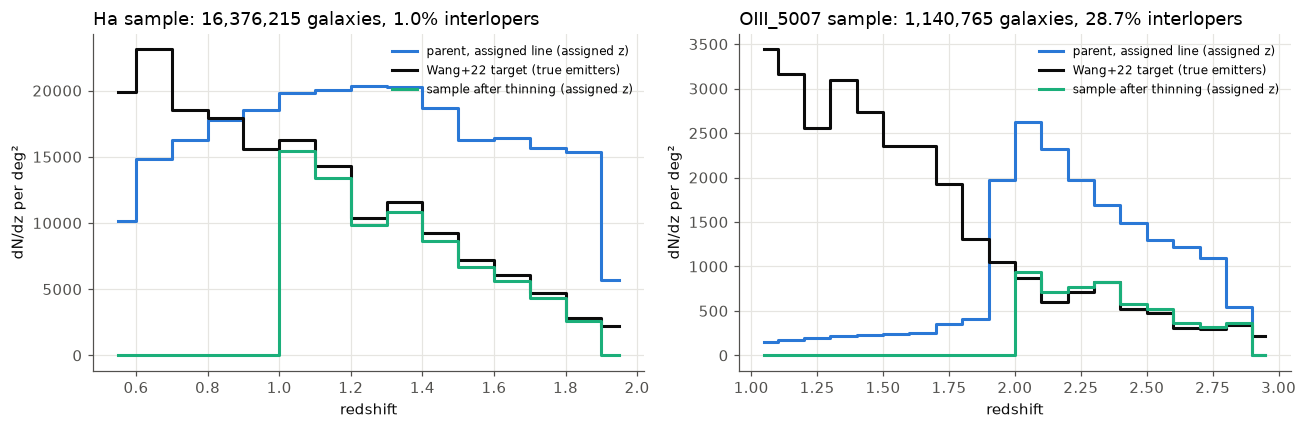

59258911607
    n_before: 55359840
    n_after: 34129888
  OIII_5007:
    z_edges:
    - 1.0
    - 1.1
    - 1.2
    - 1.3
    - 1.4
    - 1.5
    - 1.6
    - 1.7
    - 1.8
    - 1.9
    - 2.0
    - 2.1
    - 2.2
    - 2.3
    - 2.4
    - 2.5
    - 2.6
    - 2.7
    - 2.8
    - 2.9
    - 3.0
    p_keep:
    - 0.0
    - 0.0
    - 0.0
    - 0.0
    - 0.0
    - 0.0
    - 0.0
    - 0.0
    - 0.0
    - 0.5273851824030714
    - 0.3139843508125084
    - 0.25276747985288506
    - 0.3676476912984438
    - 0.5167349444672569
    - 0.4052620894573308
    - 0.4604472259887051
    - 0.34227203255757577
    - 0.38600058385422026
    - 0.962007075963518
    - 0.0
    n_before: 3177833
    n_after: 1269041



In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, path, name in zip(axes, sample_files, ["Ha", "OIII_5007"]):
    d = oc.open(path).select("redshift_assigned", "redshift_rsd", "id_outcome", "line_true").get_data("numpy", wrap_single=True)
    edges, ref = wang2022_bins(name, 1e-16, 1.65)
    zc = 0.5 * (edges[1:] + edges[:-1])
    sel = pdata["line_assigned"] == pipe.line_set.bit(name)
    ax.step(zc, dndz(pdata["redshift_assigned"][sel], edges, area), where="mid", color=plotting.CATEGORICAL[0], label="parent, assigned line (assigned z)")
    ax.step(zc, ref, where="mid", color=plotting.TEXT_PRIMARY, label="Wang+22 target (true emitters)")
    ax.step(zc, dndz(d["redshift_assigned"], edges, area), where="mid", color=plotting.CATEGORICAL[2], label="sample after thinning (assigned z)")
    misid = np.mean(d["id_outcome"] == 3)
    ax.set_xlabel("redshift"); ax.set_ylabel("dN/dz per deg²")
    ax.set_title(f"{name} sample: {len(d['redshift_assigned']):,} galaxies, {100 * misid:.1f}% interlopers"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(open(os.path.join(OUT_DIR, "samples", "halpha_z1p0_1p9_metadata.yaml")).read()[-700:])

The sample dN/dz is close to, but not identical with, the target: the sample is defined on
*assigned* redshift and contains interlopers (thinned with their own population's `p_keep`)
while missing the emitters that failed or were misidentified. That difference is the point of
keeping the two steps separate (plan comment 5). For matching a forecast of the *final* sample
instead, use the per-sample `downsample` option on `redshift_assigned`.

## Mock versus forecast, and confusion versus contamination

Two quantitative points are worth making explicit. First, how far the diffsky abundances are
from the Galacticus forecast: the ratio of the mock's detected-emitter dN/dz to the Wang et al.
table per bin. Ratios above one are what thinning removes; ratios below one are shortages that
thinning cannot fill (the pipeline warns about them).

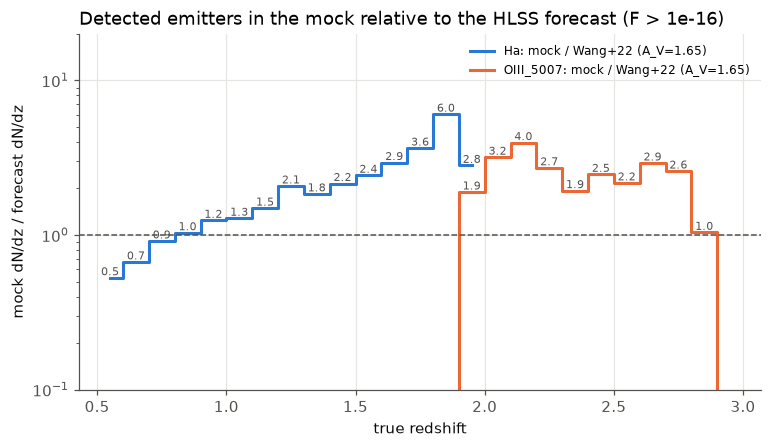

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for name in ["Ha", "OIII_5007"]:
    edges, ref = wang2022_bins(name, 1e-16, 1.65)
    zc = 0.5 * (edges[1:] + edges[:-1])
    sel = pdata["line_true"] == pipe.line_set.bit(name)
    ratio = dndz(pdata["redshift_rsd"][sel], edges, area) / ref
    ax.step(zc, ratio, where="mid", color=plotting.feature_color(name), label=f"{name}: mock / Wang+22 (A_V=1.65)")
    for z, r in zip(zc, ratio):
        if 0 < r < 100:
            ax.text(z, r, f"{r:.1f}", fontsize=7, ha="center", va="bottom", color=plotting.TEXT_SECONDARY)
ax.axhline(1.0, color=plotting.TEXT_SECONDARY, lw=1, ls="--")
ax.set_yscale("log"); ax.set_ylim(0.1, 20)
ax.set_xlabel("true redshift"); ax.set_ylabel("mock dN/dz / forecast dN/dz")
ax.set_title("Detected emitters in the mock relative to the HLSS forecast (F > 1e-16)"); ax.legend(fontsize=8)
plt.show()

Second, why the [O III] sample is far more contaminated than the confusion matrix alone suggests.
The matrix says a single-line Hα emitter is called [O III] with probability 5 %. But the sample of
galaxies *assigned* [O III] at assigned redshift 2–2.9 draws its interlopers from single-line Hα emitters at
z_rsd ≈ 1.3–1.95 (the redshifts that map onto 2–2.9 through λ_Hα/λ_[O III]), and those are many
times more numerous than the true [O III] emitters at z ≈ 2–2.9, even after thinning. The
contamination fraction is the abundance-weighted quantity

f(Hα → [O III]) = N_Hα,single(z_src) · C(Hα→[O III]) / N_sample([O III]),

which is plan comment 4 and review item 4: a fixed confusion matrix does not imply a fixed
interloper fraction.

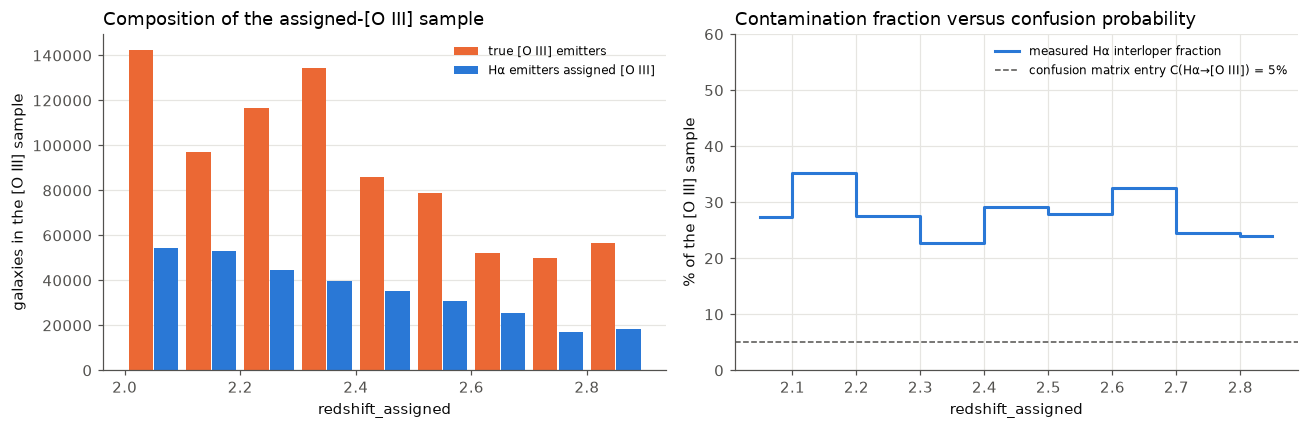

[O III] sample: 1,140,765 galaxies; true [O III] 813,713; Hα interlopers 318,555 (27.9%), from a source population of single-line Hα emitters at z_rsd ~ 1.29-1.98
single-line Hα emitters in the parent at those redshifts (before thinning): 17,358,752; x C(Hα→[O III]) = 0.05 -> 867,938 interlopers before thinning, versus 813,713 true [O III] emitters kept


In [14]:
from romanmock import IdOutcome

i_ha, i_o3 = pipe.line_set.bit("Ha"), pipe.line_set.bit("OIII_5007")
d = oc.open(sample_files[1]).select("redshift_assigned", "redshift_rsd", "line_true", "id_outcome").get_data("numpy", wrap_single=True)
edges = np.linspace(2.0, 2.9, 10)
zc = 0.5 * (edges[1:] + edges[:-1])
true_o3 = d["line_true"] == i_o3
ha_interloper = (d["line_true"] == i_ha) & (d["id_outcome"] == IdOutcome.SINGLE_MISID)
n_true, _ = np.histogram(d["redshift_assigned"][true_o3], bins=edges)
n_int, _ = np.histogram(d["redshift_assigned"][ha_interloper], bins=edges)
n_all, _ = np.histogram(d["redshift_assigned"], bins=edges)

# source population: single-line Hα emitters (after thinning) at the redshifts that map into each bin
lam_ratio = pipe.line_set["Ha"].rest_wave / pipe.line_set["OIII_5007"].rest_wave
src_edges = (1 + edges) / lam_ratio - 1
c_ha_o3 = pipe.confusion.matrix[i_ha, i_o3]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
w = np.diff(edges)
ax1.bar(zc - 0.22 * w, n_true, width=0.42 * w, color=plotting.feature_color("OIII_5007"), label="true [O III] emitters")
ax1.bar(zc + 0.22 * w, n_int, width=0.42 * w, color=plotting.feature_color("Ha"), label="Hα emitters assigned [O III]")
ax1.set_xlabel("redshift_assigned"); ax1.set_ylabel("galaxies in the [O III] sample"); ax1.set_title("Composition of the assigned-[O III] sample"); ax1.legend(fontsize=8)
ax1.grid(axis="x", visible=False)
ax2.step(zc, 100 * n_int / n_all, where="mid", color=plotting.feature_color("Ha"), label="measured Hα interloper fraction")
ax2.axhline(100 * c_ha_o3, color=plotting.TEXT_SECONDARY, ls="--", lw=1, label=f"confusion matrix entry C(Hα→[O III]) = {100 * c_ha_o3:.0f}%")
ax2.set_ylim(0, 60); ax2.set_xlabel("redshift_assigned"); ax2.set_ylabel("% of the [O III] sample"); ax2.set_title("Contamination fraction versus confusion probability"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"[O III] sample: {n_all.sum():,} galaxies; true [O III] {n_true.sum():,}; Hα interlopers {n_int.sum():,} "
      f"({100 * n_int.sum() / n_all.sum():.1f}%), from a source population of single-line Hα emitters at z_rsd ~ {src_edges[0]:.2f}-{src_edges[-1]:.2f}")
n_src = np.sum((pdata['line_true'] == i_ha) & (pdata['n_det'] == 1) & (pdata['redshift_rsd'] >= src_edges[0]) & (pdata['redshift_rsd'] <= src_edges[-1]))
print(f"single-line Hα emitters in the parent at those redshifts (before thinning): {n_src:,}; "
      f"x C(Hα→[O III]) = {c_ha_o3:.2f} -> {n_src * c_ha_o3:,.0f} interlopers before thinning, versus {n_true.sum():,} true [O III] emitters kept")

So the 5 % matrix entry becomes a ~30 % contamination because the source population is an order of
magnitude larger than the target population. Lowering the interloper fraction in this scenario
requires either a smaller C(Hα→[O III]) (the calibration the plan calls the main external input),
or the extra information the comments suggest (photometric redshifts, missing companion lines)
entering the confusion model; thinning to a forecast dN/dz does not change it.

The sample files retain `ra`, `dec`, `redshift_true`, `redshift_rsd`, `redshift_assigned` and `id_outcome` by default
(`output.sample_columns`); the parent catalog additionally has `line_bitmask`, `line_true`,
`line_assigned` and `id_outcome`, so completeness, contamination and clustering can be checked
against the truth (plan section 4). Open them with `opencosmo.open(path)`.